# **3. Обробка та класифікація текстових даних**

У цьому розділі буде розглянуто методи обробки та класифікації текстових даних. Для дослідження використовується набір даних [BBC News Classification Dataset](https://huggingface.co/datasets/SetFit/bbc-news), який містить новинні статті англійською мовою, розподілені за п'ятьма тематичними категоріями: business, entertainment, politics, sport та tech.

Основною метою є виконання попередньої обробки текстів, візуалізація характерних слів за допомогою WordCloud, перетворення текстових даних у числові ознаки методом TF-IDF та побудова моделі класифікації.

Для оцінювання якості моделі будуть використані відповідні метрики класифікації.

In [ ]:

import pandas as pd
from datasets import load_dataset

dataset = load_dataset("SetFit/bbc-news")

df_text = pd.concat(
    [split.to_pandas() for split in dataset.values()],
    ignore_index=True
)

# Залишаємо текст статті та назву її категорії
df_text = df_text[["text", "label_text"]].rename(
    columns={"label_text": "category"}
)

print("Розмір датасету:", df_text.shape)

print("\nПерші 5 записів:")
display(df_text.head())

print("\nКількість статей за категоріями:")
print(df_text["category"].value_counts())


README.md:   0%|          | 0.00/880 [00:00<?, ?B/s]

train.jsonl:   0%|          | 0.00/2.87M [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/2.28M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1225 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Розмір датасету: (2225, 2)

Перші 5 записів:


,text,category
0,wales want rugby league training wales could f...,sport
1,china aviation seeks rescue deal scandal-hit j...,business
2,rock band u2 break ticket record u2 have smash...,entertainment
3,markets signal brazilian recovery the brazilia...,business
4,tough rules for ringtone sellers firms that fl...,tech



Кількість статей за категоріями:
category
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64



# **3.1. Перевірка пропущених значень**

На цьому етапі виконаємо очищення текстів: видалимо пропущені та дубльовані записи, пунктуацію і стоп-слова, а також приведемо текст до нижнього регістру. Підготовлені дані використовуватимуться для подальшої візуалізації та класифікації.


In [ ]:
import re
import string
import nltk

from nltk.corpus import stopwords

# Завантаження англійських стоп-слів
nltk.download("stopwords", quiet=True)
stop_words = set(stopwords.words("english"))

# Видалення пропущених і дубльованих записів
df_text = df_text.dropna(subset=["text", "category"]).drop_duplicates().copy()

# Функція очищення тексту
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\d+", " ", text)
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return " ".join(words)

df_text["clean_text"] = df_text["text"].apply(preprocess_text)

print("Розмір датасету після очищення:", df_text.shape)
print("\nКількість записів за категоріями:")
print(df_text["category"].value_counts())

display(df_text[["category", "clean_text"]].head())


Розмір датасету після очищення: (2126, 3)

Кількість записів за категоріями:
category
sport            504
business         503
politics         403
entertainment    369
tech             347
Name: count, dtype: int64


,category,clean_text
0,sport,wales want rugby league training wales could f...
1,business,china aviation seeks rescue deal scandalhit je...
2,entertainment,rock band u break ticket record u smashed iris...
3,business,markets signal brazilian recovery brazilian st...
4,tech,tough rules ringtone sellers firms flout rules...


# **3.2. Візуалізація текстових даних за допомогою WordCloud**

Для кожної категорії новин побудуємо WordCloud, яка відображає найчастіше вживані слова. Це дозволить визначити основні тематичні особливості статей у кожному класі.

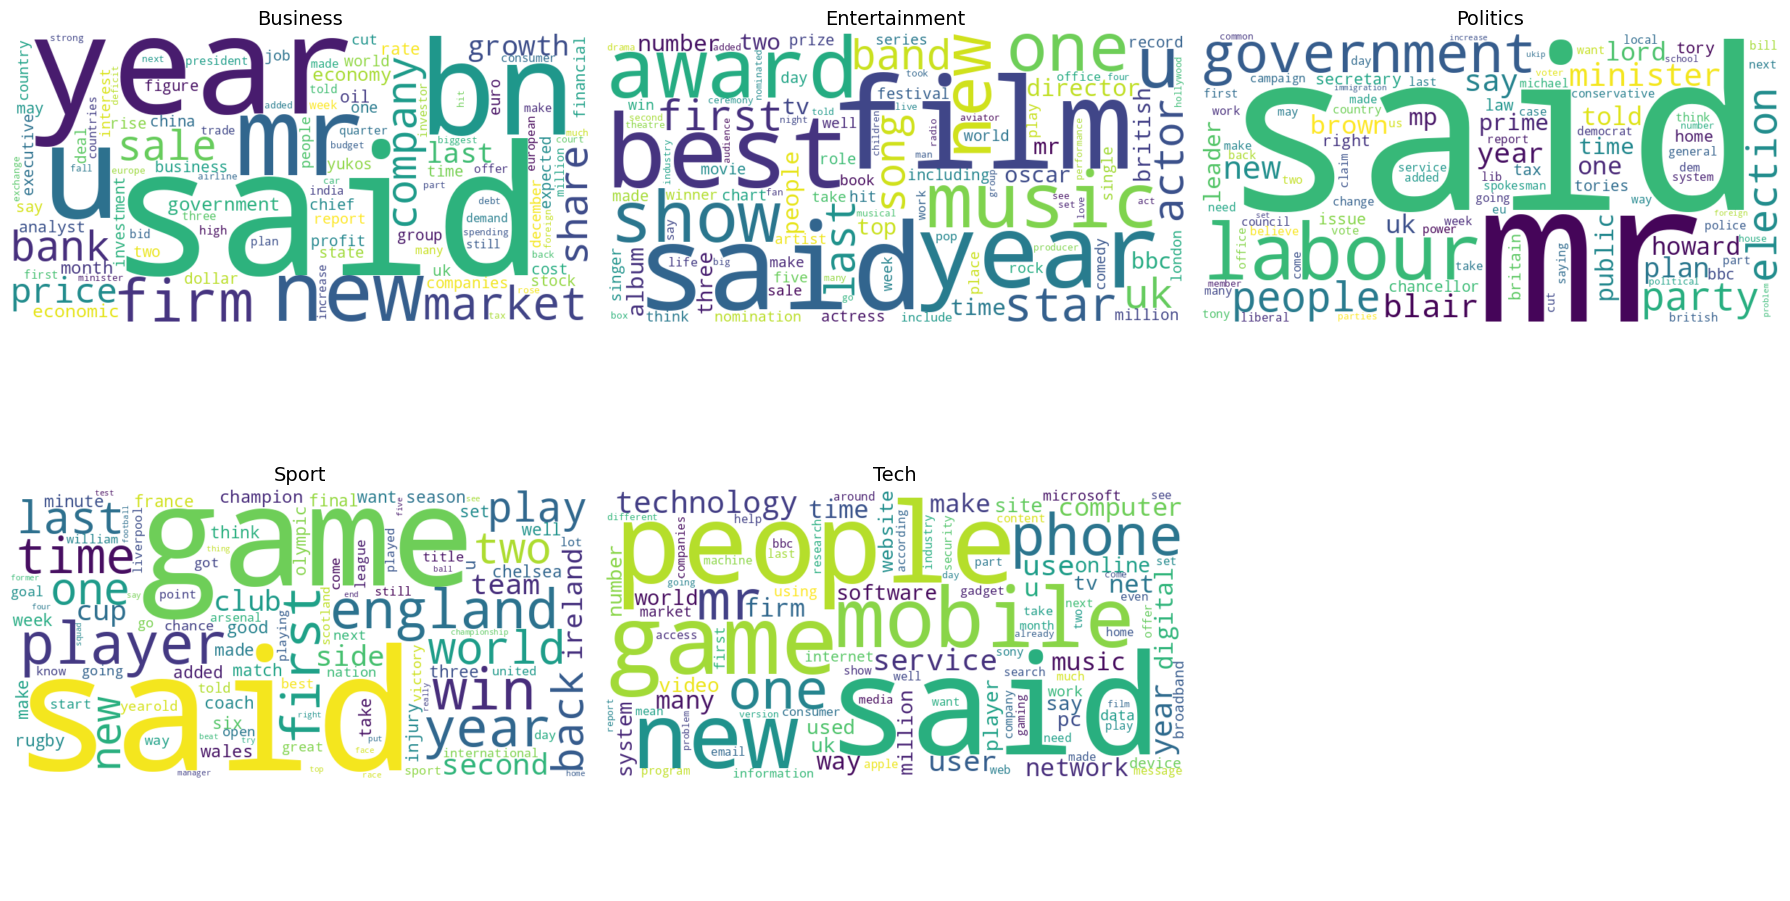

In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Об'єднання текстів у межах кожної категорії
categories = sorted(df_text["category"].unique())

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, category in enumerate(categories):
    text = " ".join(
        df_text.loc[df_text["category"] == category, "clean_text"]
    )

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white",
        max_words=100,
        collocations=False
    ).generate(text)

    axes[i].imshow(wordcloud, interpolation="bilinear")
    axes[i].set_title(category.capitalize(), fontsize=14)
    axes[i].axis("off")

axes[-1].axis("off")

plt.tight_layout()
plt.show()

# **Аналіз результатів візуалізації.**

Отримані хмари слів демонструють відмінності між тематичними категоріями новин. Для категорії business характерні слова, пов'язані з економікою та фінансами, для entertainment — з кіно, музикою та розвагами, для politics — з урядом і політичними партіями, для sport — зі спортивними змаганнями, а для tech — з мобільними пристроями та цифровими технологіями.

Водночас деякі слова, наприклад said, people та new, зустрічаються в кількох категоріях, оскільки мають загальний характер і часто використовуються в новинних текстах.

Таким чином, WordCloud дозволяє виявити основні тематичні особливості кожного класу та підтверджує доцільність подальшої класифікації текстів.

# **3.3. Векторизація текстів та побудова моделі класифікації**

Для перетворення текстів у числові ознаки використаємо метод TF-IDF. Для класифікації новин застосуємо алгоритм LinearSVC, який ефективно працює з розрідженими текстовими ознаками.

Accuracy: 0.9883
Precision (macro): 0.9876
Recall (macro): 0.9896
F1-score (macro): 0.9885

Звіт класифікації:
               precision    recall  f1-score   support

     business       0.99      0.97      0.98       101
entertainment       0.99      1.00      0.99        74
     politics       0.98      0.99      0.98        81
        sport       1.00      0.99      1.00       101
         tech       0.99      1.00      0.99        69

     accuracy                           0.99       426
    macro avg       0.99      0.99      0.99       426
 weighted avg       0.99      0.99      0.99       426



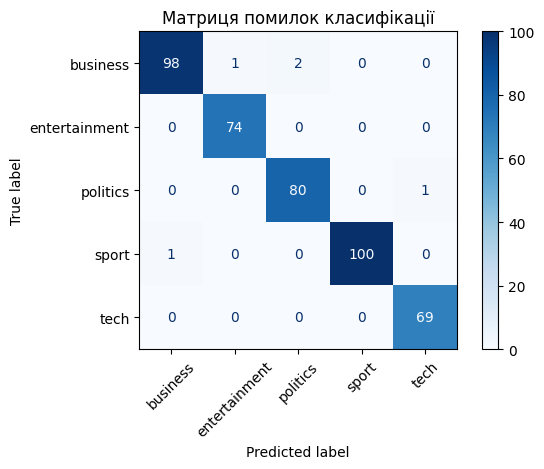

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

X_train, X_test, y_train, y_test = train_test_split(
    df_text["clean_text"],
    df_text["category"],
    test_size=0.2,
    random_state=42,
    stratify=df_text["category"]
)

# Створення конвеєра TF-IDF та LinearSVC
text_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=30000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(C=1.0))
])

text_model.fit(X_train, y_train)

y_pred = text_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision (macro):", round(precision_score(y_test, y_pred, average="macro"), 4))
print("Recall (macro):", round(recall_score(y_test, y_pred, average="macro"), 4))
print("F1-score (macro):", round(f1_score(y_test, y_pred, average="macro"), 4))

print("\nЗвіт класифікації:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    xticks_rotation=45
)
plt.title("Матриця помилок класифікації")
plt.tight_layout()
plt.show()

# **Аналіз результатів класифікації**

Після навчання моделі LinearSVC отримано високі показники якості класифікації. Значення Accuracy становить 0.9883, Precision — 0.9876, Recall — 0.9896, а F1-score — 0.9885.

Матриця помилок показує, що з 426 тестових прикладів правильно класифіковано 421. Найкращі результати отримано для категорій entertainment та tech, де всі статті були класифіковані правильно. Найбільше помилок спостерігається для категорії business.

Отримані результати свідчать про високу ефективність методу TF-IDF у поєднанні з алгоритмом LinearSVC для класифікації новинних текстів. Модель успішно розрізняє п'ять тематичних категорій новин.

# **ВИСНОВКИ**

У ході виконання лабораторної роботи було досліджено методи зниження розмірності даних, кластеризації та класифікації текстової інформації за допомогою бібліотек Python та інструментів машинного навчання.

Під час першої частини роботи було виконано зниження розмірності набору даних Phishing Websites за допомогою методу головних компонент та алгоритму t-SNE. Метод PCA дозволив зменшити кількість ознак із 30 до 23, зберігши понад 95% початкової дисперсії даних. Також було проведено порівняння результатів класифікації до та після застосування PCA. Отримані результати показали, що зменшення розмірності дозволяє скоротити кількість ознак із незначною втратою якості класифікації.

У другій частині роботи було застосовано алгоритм K-Means для кластеризації даних. Проведено оцінювання результатів за допомогою коефіцієнта силуету та скоригованого індексу Ренда (ARI). Серед перевірених варіантів найкращий результат за ARI отримано для чотирьох кластерів. Візуалізація за допомогою t-SNE дозволила дослідити розташування об'єктів у просторі зниженої розмірності.

У третій частині роботи було досліджено методи обробки та класифікації текстових даних на прикладі набору BBC News Classification Dataset. Виконано очищення текстів від пунктуації та стоп-слів, побудовано хмари слів WordCloud для п'яти тематичних категорій. Для перетворення текстів у числові ознаки використано метод TF-IDF, а для класифікації — алгоритм LinearSVC. Модель продемонструвала високі результати: Accuracy — 0.9883, Precision — 0.9876, Recall — 0.9896 та F1-score — 0.9885.

Протягом реалізації умов та положень лабораторної роботи було закріплено практичні навички зниження розмірності, кластеризації та класифікації даних. Проведені експерименти продемонстрували можливості методів PCA, t-SNE, K-Means, TF-IDF та LinearSVC для аналізу структурованих і текстових даних.